# Rain Prediction — Spatial design tuning + fresh hyperparameter search (EXP-007)

EXP-006 showed spatial neighbour features broke the same-station ceiling (chronological
PR-AUC 0.741 -> 0.761), driven by **same-day** neighbour humidity/pressure. Two levers remain:

1. **Spatial design** — sweep `K` (1/3/5/7) and try **directional upstream (westerly)** neighbours
   instead of omnidirectional nearest (mid-latitude weather advects W->E).
2. **Fresh hyperparameter search** on the full 44-feature set — the XGBoost config has been frozen
   since EXP-002, *before any spatial features existed*.

Same corrected both-splits harness; chronological is the headline (spatial features are an
interpolation aid that does not transfer to unseen stations — EXP-006). Logs -> `SPTUNE_result.txt`,
figures `sptune_*`. Colab GPU.


## 1. Setup, imports, constants

In [1]:
# --- Colab environment setup ---
import subprocess, sys as _sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([_sys.executable, '-m', 'pip', '-q', 'install', '-U', 'xgboost'], check=False)
    subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'], check=False)
    # from google.colab import drive; drive.mount('/content/drive')
print(f'Running on Colab: {IN_COLAB}')

Running on Colab: True


In [2]:
import os, sys, zipfile, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    TimeSeriesSplit, GroupKFold, GroupShuffleSplit, RandomizedSearchCV)
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score,
    roc_curve, precision_recall_curve, auc)
import xgboost as xgb
from xgboost import XGBClassifier
warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')

RANDOM_STATE = 42
TEST_CUTOFF = pd.Timestamp('2016-01-01')

def _gpu_available():
    try:
        d = xgb.DMatrix(np.zeros((8, 2)), label=np.zeros(8))
        xgb.train({'device': 'cuda', 'tree_method': 'hist'}, d, num_boost_round=1)
        return True
    except Exception as e:
        print(f'CUDA probe failed ({type(e).__name__}); CPU fallback.'); return False

USE_GPU = _gpu_available()
DEVICE = 'cuda' if USE_GPU else 'cpu'
SEARCH_N_JOBS = 1 if USE_GPU else -1
XGB_KW = dict(tree_method='hist', device=DEVICE, eval_metric='logloss',
              random_state=RANDOM_STATE, n_jobs=-1)
def make_xgb(**ov):
    p = dict(XGB_KW); p.update(ov); return XGBClassifier(**p)

# Frozen EXP-002 config (the K-sweep baseline; the fresh search will try to beat it).
V2_PARAMS = dict(max_depth=6, min_child_weight=10, gamma=2.0, reg_lambda=20, reg_alpha=0.5,
                 learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, n_estimators=800)
print(f'xgboost {xgb.__version__} | device: {DEVICE}')

xgboost 3.3.0 | device: cuda


### Output setup

In [3]:
os.makedirs('figures', exist_ok=True)
_PATH = 'SPTUNE_result.txt'
_FILE = open(_PATH, 'w', encoding='utf-8')
class _Tee:
    def __init__(self, *s): self._s = s
    def write(self, d):
        for s in self._s: s.write(d)
    def flush(self):
        for s in self._s: s.flush()
    def isatty(self): return False
_ORIG = sys.stdout; sys.stdout = _Tee(_ORIG, _FILE)
print('# Spatial tuning + fresh search — numerical outputs')
print(f'# Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
def log_section(t):
    print('\n' + '=' * 72 + '\n' + t + '\n' + '=' * 72)
def save_fig(name, fig=None):
    fig = fig or plt.gcf(); p = f'figures/{name}.png'
    fig.savefig(p, dpi=150, bbox_inches='tight'); print(f'  [saved {p}]')

# Spatial tuning + fresh search — numerical outputs
# Generated: 2026-06-20 13:43:51


## 2. Load + base + temporal features

In [ ]:
log_section('2. Load + base + temporal features')

# Sur Colab : monter le Drive. En local : lire ../../data/, alimenté par
# 3.preprocessing_trend_group.ipynb et 4_preprocessing_imputation.ipynb.
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = "/content/drive/MyDrive/Colab_Notebooks"
else:
    DATA_DIR = "../../data"

PRE_PATH = f"{DATA_DIR}/weatherAUS_MICE_cyclic.csv"
RAW_PATH = f"{DATA_DIR}/weatherAUS.csv"

raw = pd.read_csv(RAW_PATH); raw['Date'] = pd.to_datetime(raw['Date'])
df  = pd.read_csv(PRE_PATH); df['Date'] = pd.to_datetime(df['Date'])
df['RainTomorrow'] = df['RainTomorrow'].astype(bool)

if 'Date_sin' not in df.columns:
    d = df['Date'].dt.dayofyear
    df['Date_sin'] = np.sin(2*np.pi*d/365.25); df['Date_cos'] = np.cos(2*np.pi*d/365.25)
df['Pressure_diff'] = df['Pressure3pm'] - df['Pressure9am']
df['Temp_diff']     = df['Temp3pm']     - df['Temp9am']
BASE_FEATURES = ['MinTemp','MaxTemp','Rainfall','Evaporation','Sunshine','WindGustSpeed',
    'WindSpeed9am','WindSpeed3pm','Humidity3pm','Pressure9am','Pressure3pm','Cloud9am','Cloud3pm',
    'Temp9am','Temp3pm','Date_sin','Date_cos','WindGustDir_sin','WindGustDir_cos','WindDir9am_sin',
    'WindDir9am_cos','WindDir3pm_sin','WindDir3pm_cos','Pressure_diff','Temp_diff']

raw_s = raw.sort_values(['Location', 'Date']).copy()
g = raw_s.groupby('Location', sort=False)
feat = pd.DataFrame({'Date': raw_s['Date'].values, 'Location': raw_s['Location'].values})
for c in ['Humidity3pm','Pressure3pm','Rainfall','Cloud3pm','Sunshine','Temp3pm','WindGustSpeed']:
    feat[f'{c}_lag1'] = g[c].shift(1).values
feat['Pressure_3d_chg']  = (g['Pressure3pm'].shift(1) - g['Pressure3pm'].shift(4)).values
feat['Humidity_3d_mean'] = g['Humidity3pm'].apply(lambda s: s.shift(1).rolling(3).mean()).values
feat['Rainfall_3d_sum']  = g['Rainfall'].apply(lambda s: s.shift(1).rolling(3).sum()).values
rt = raw_s['RainToday'].map({'Yes': 1, 'No': 0})
rt_lag = rt.groupby(raw_s['Location'], sort=False).shift(1)
feat['RainToday_lag1'] = rt_lag.values
def _days_since(s):
    out = np.empty(len(s)); cnt = 9999.0
    for i, v in enumerate(s.to_numpy()):
        out[i] = cnt; cnt = 0.0 if v == 1 else (cnt + 1 if cnt < 9999 else 9999)
    return out
feat['days_since_rain'] = (
    rt_lag.fillna(0).groupby(raw_s['Location'], sort=False).transform(lambda s: _days_since(s)).values)
TEMPORAL_FEATURES = [c for c in feat.columns if c not in ('Date', 'Location')]
df = df.merge(feat, on=['Date', 'Location'], how='left')
print(f'BASE {len(BASE_FEATURES)} | TEMPORAL {len(TEMPORAL_FEATURES)}')

## 3. Geocoding + neighbour graphs (K=1,3,5,7 nearest, and K=3 upstream-west)

In [5]:
log_section('3. Neighbour graphs')
COORDS = {
    'Adelaide': (-34.9285, 138.6007), 'Albany': (-35.0269, 117.8837), 'Albury': (-36.0737, 146.9135),
    'AliceSprings': (-23.6980, 133.8807), 'BadgerysCreek': (-33.8829, 150.7609), 'Ballarat': (-37.5622, 143.8503),
    'Bendigo': (-36.7570, 144.2794), 'Brisbane': (-27.4698, 153.0251), 'Cairns': (-16.9186, 145.7781),
    'Canberra': (-35.2809, 149.1300), 'Cobar': (-31.4958, 145.8389), 'CoffsHarbour': (-30.2986, 153.1094),
    'Dartmoor': (-37.9225, 141.2767), 'Darwin': (-12.4634, 130.8456), 'GoldCoast': (-28.0167, 153.4000),
    'Hobart': (-42.8821, 147.3272), 'Katherine': (-14.4652, 132.2635), 'Launceston': (-41.4332, 147.1441),
    'Melbourne': (-37.8136, 144.9631), 'MelbourneAirport': (-37.6690, 144.8410), 'Mildura': (-34.1855, 142.1625),
    'Moree': (-29.4639, 149.8407), 'MountGambier': (-37.8284, 140.7820), 'MountGinini': (-35.5294, 148.7723),
    'Newcastle': (-32.9283, 151.7817), 'Nhil': (-36.3333, 141.6500), 'NorahHead': (-33.2833, 151.5667),
    'NorfolkIsland': (-29.0408, 167.9547), 'Nuriootpa': (-34.4700, 138.9960), 'PearceRAAF': (-31.6676, 116.0292),
    'Penrith': (-33.7507, 150.6877), 'Perth': (-31.9505, 115.8605), 'PerthAirport': (-31.9385, 115.9672),
    'Portland': (-38.3609, 141.6041), 'Richmond': (-33.6000, 150.7667), 'Sale': (-38.1026, 147.0730),
    'SalmonGums': (-32.9815, 121.6438), 'Sydney': (-33.8688, 151.2093), 'SydneyAirport': (-33.9399, 151.1753),
    'Townsville': (-19.2590, 146.8169), 'Tuggeranong': (-35.4244, 149.0888), 'Uluru': (-25.3444, 131.0369),
    'WaggaWagga': (-35.1082, 147.3598), 'Walpole': (-34.9777, 116.7338), 'Watsonia': (-37.7100, 145.0830),
    'Williamtown': (-32.8150, 151.8428), 'Witchcliffe': (-34.0261, 115.1003), 'Wollongong': (-34.4278, 150.8931),
    'Woomera': (-31.1656, 136.8193),
}
assert set(df['Location'].unique()) <= set(COORDS)
stations = sorted(COORDS)
def haversine(a, b):
    R = 6371.0; p1, p2 = np.radians(a[0]), np.radians(b[0])
    dphi = np.radians(b[0]-a[0]); dl = np.radians(b[1]-a[1])
    h = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*R*np.arcsin(np.sqrt(h))

def knn(K, west_only=False):
    nb, nd = {}, {}
    for s in stations:
        cand = sorted((haversine(COORDS[s], COORDS[t]), t) for t in stations if t != s)
        nd[s] = cand[0][0]
        if west_only:
            west = [t for _, t in cand if COORDS[t][1] < COORDS[s][1]]
            rest = [t for _, t in cand if COORDS[t][1] >= COORDS[s][1]]
            nb[s] = (west + rest)[:K]
        else:
            nb[s] = [t for _, t in cand][:K]
    return nb, nd

GRAPHS = {f'K{K}': knn(K)[0] for K in (1, 3, 5, 7)}
GRAPHS['K3_west'] = knn(3, west_only=True)[0]
NEAREST_DIST = knn(1)[1]
print('graphs:', list(GRAPHS))
print('  Sydney  K3      :', GRAPHS['K3']['Sydney'])
print('  Sydney  K3_west :', GRAPHS['K3_west']['Sydney'])

## 4. Spatial feature builder (parameterized by neighbour graph)

Pivots are precomputed once; each graph just re-aggregates. nanmean over neighbours, same-day
`_t` + lagged `_t1`, plus static `nearest_dist`.

In [6]:
log_section('4. Spatial feature builder')
raw2 = raw.assign(_RainToday=raw['RainToday'].map({'Yes': 1, 'No': 0}))
full_dates = pd.date_range(raw['Date'].min(), raw['Date'].max(), freq='D')
WIDE = {var: (raw2.pivot_table(index='Date', columns='Location', values=var, dropna=False)
             .reindex(index=full_dates, columns=stations))
        for var in ['Rainfall', 'Pressure3pm', 'Humidity3pm', '_RainToday']}
SPEC = [('Rainfall', False), ('Rainfall', True), ('Pressure3pm', False),
        ('Pressure3pm', True), ('Humidity3pm', False), ('_RainToday', False)]

def build_spatial(neighbours):
    out = df[['Date', 'Location']].copy()
    cols = []
    for var, lag in SPEC:
        wide = WIDE[var]
        agg = pd.DataFrame({s: wide[neighbours[s]].mean(axis=1) for s in stations}, index=wide.index)
        if lag:
            agg = agg.shift(1)
        agg.index.name = 'Date'
        name = f'nbr_{var.replace("_RainToday","RainToday")}_{"t1" if lag else "t"}'
        out = out.merge(agg.reset_index().melt(id_vars='Date', var_name='Location', value_name=name),
                        on=['Date', 'Location'], how='left')
        cols.append(name)
    out['nearest_dist'] = out['Location'].map(NEAREST_DIST); cols.append('nearest_dist')
    return out, cols
print('builder ready')

## 5. Helpers + split masks

In [7]:
def masks_and_y():
    ds = df.sort_values('Date').reset_index(drop=True)
    return ds, (ds['Date'] < TEST_CUTOFF).values, ds['RainTomorrow'].astype(int), ds['Location']

def light_eval(Xtr, ytr, Xte, yte, params=None):
    m = make_xgb(**(params or V2_PARAMS), scale_pos_weight=(1-ytr.mean())/ytr.mean())
    m.fit(Xtr, ytr); proba = m.predict_proba(Xte)[:, 1]
    p, r, _ = precision_recall_curve(yte, proba)
    return round(roc_auc_score(yte, proba), 4), round(auc(r, p), 4)

def pr_crossover_threshold(params, Xtr, ytr, cv, groups, grid=np.arange(0.10, 0.81, 0.01)):
    recs = []
    for tr, va in cv.split(Xtr, ytr, groups):
        m = make_xgb(**params); m.fit(Xtr.iloc[tr], ytr.iloc[tr])
        recs.append((ytr.iloc[va].values, m.predict_proba(Xtr.iloc[va])[:, 1]))
    best_t, best_d = 0.5, 1e9
    for t in grid:
        P = np.mean([precision_score(y, p >= t, zero_division=0) for y, p in recs])
        R = np.mean([recall_score(y, p >= t) for y, p in recs])
        F = np.mean([f1_score(y, p >= t) for y, p in recs])
        d = abs(P - F) + abs(F - R)
        if d < best_d: best_t, best_d = float(t), d
    return round(best_t, 2)

def full_eval(cols, params, split, ds, y_all, loc_all):
    if split == 'chronological':
        tr = (ds['Date'] < TEST_CUTOFF).values; cv, groups = TimeSeriesSplit(5), None
    else:
        gss = GroupShuffleSplit(1, test_size=0.2, random_state=RANDOM_STATE)
        a, _ = next(gss.split(ds, y_all, groups=loc_all))
        tr = np.zeros(len(ds), bool); tr[a] = True
        cv = GroupKFold(5)
    X = ds[cols]
    Xtr, Xte = X[tr].reset_index(drop=True), X[~tr].reset_index(drop=True)
    ytr, yte = y_all[tr].reset_index(drop=True), y_all[~tr].reset_index(drop=True)
    pr = dict(params); pr['scale_pos_weight'] = (1-ytr.mean())/ytr.mean()
    groups = None if split == 'chronological' else loc_all[tr].reset_index(drop=True)
    t = pr_crossover_threshold(pr, Xtr, ytr, cv, groups)
    m = make_xgb(**pr); m.fit(Xtr, ytr); proba = m.predict_proba(Xte)[:, 1]; pred = (proba >= t).astype(int)
    p, r, _ = precision_recall_curve(yte, proba)
    return dict(split=split, threshold=t, F1=round(f1_score(yte, pred), 4),
                precision=round(precision_score(yte, pred), 4), recall=round(recall_score(yte, pred), 4),
                ROC_AUC=round(roc_auc_score(yte, proba), 4), PR_AUC=round(auc(r, p), 4)), m
print('helpers ready')

## 6. K sweep + directional (chronological, frozen config, ROC/PR)

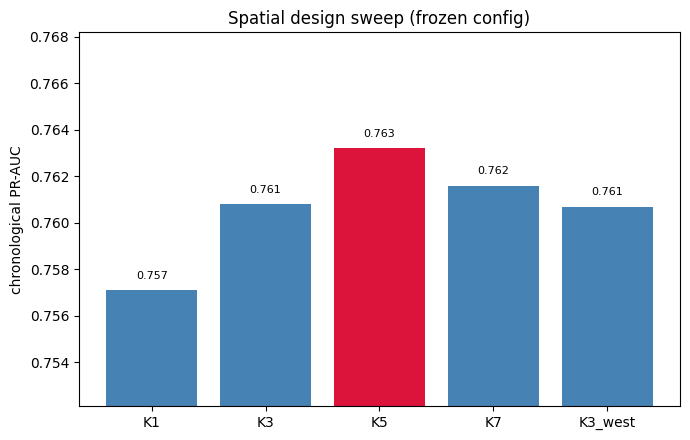

In [8]:
log_section('6. Spatial design sweep (chronological)')
rows = []
SPATIAL_COLS = {}
for gname, graph in GRAPHS.items():
    sdf, scols = build_spatial(graph)
    d2 = df.merge(sdf, on=['Date', 'Location'], how='left').sort_values('Date').reset_index(drop=True)
    cols = BASE_FEATURES + TEMPORAL_FEATURES + scols
    tr = (d2['Date'] < TEST_CUTOFF).values
    y = d2['RainTomorrow'].astype(int)
    roc, pr = light_eval(d2[cols][tr].reset_index(drop=True), y[tr].reset_index(drop=True),
                         d2[cols][~tr].reset_index(drop=True), y[~tr].reset_index(drop=True))
    rows.append({'graph': gname, 'n_nbr': len(next(iter(graph.values()))), 'ROC_AUC': roc, 'PR_AUC': pr})
    SPATIAL_COLS[gname] = scols
    print(f'  {gname:10s} -> ROC {roc:.4f}  PR {pr:.4f}')
sweep = pd.DataFrame(rows)
print('\n' + sweep.to_string(index=False))
best_graph = sweep.loc[sweep['PR_AUC'].idxmax(), 'graph']
print(f'\nBest spatial graph by PR-AUC: {best_graph}')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(sweep['graph'], sweep['PR_AUC'], color=['steelblue' if gname != best_graph else 'crimson' for gname in sweep['graph']])
ax.set_ylabel('chronological PR-AUC'); ax.set_title('Spatial design sweep (frozen config)')
ax.set_ylim(sweep['PR_AUC'].min()-0.005, sweep['PR_AUC'].max()+0.005)
for i, v in enumerate(sweep['PR_AUC']): ax.text(i, v+0.0005, f'{v:.3f}', ha='center', fontsize=8)
plt.tight_layout(); save_fig('sptune_01_design_sweep', fig); plt.show()

## 7. Fresh hyperparameter search on the winning 44-feature set

In [9]:
log_section('7. Fresh RandomizedSearchCV (winning spatial graph)')
sdf, scols = build_spatial(GRAPHS[best_graph])
dW = df.merge(sdf, on=['Date', 'Location'], how='left').sort_values('Date').reset_index(drop=True)
WIN_COLS = BASE_FEATURES + TEMPORAL_FEATURES + scols
trm = (dW['Date'] < TEST_CUTOFF).values
y_all = dW['RainTomorrow'].astype(int); loc_all = dW['Location']
Xtr_w = dW[WIN_COLS][trm].reset_index(drop=True); ytr_w = y_all[trm].reset_index(drop=True)
SPW = (1 - ytr_w.mean()) / ytr_w.mean()

param_dist = {
    'n_estimators': [400, 600, 800, 1200], 'max_depth': [4, 5, 6, 8],
    'learning_rate': [0.02, 0.03, 0.05], 'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.5, 0.7, 0.9], 'min_child_weight': [3, 5, 10, 20],
    'gamma': [0, 0.5, 1.0, 2.0], 'reg_lambda': [1, 5, 10, 20], 'reg_alpha': [0, 0.5, 1.0],
    'scale_pos_weight': [SPW],
}
search = RandomizedSearchCV(make_xgb(), param_dist, n_iter=40, scoring='f1',
                            cv=TimeSeriesSplit(5), n_jobs=SEARCH_N_JOBS,
                            random_state=RANDOM_STATE, verbose=1)
search.fit(Xtr_w, ytr_w)
TUNED = {k: v for k, v in search.best_params_.items()}
print(f'Best params: {search.best_params_}')
print(f'Best CV F1 : {search.best_score_:.4f}  (EXP-006 frozen-config CV ~0.653)')

## 8. Final comparison — frozen vs tuned config, both splits

In [10]:
log_section('8. Final — frozen vs tuned (winning spatial graph)')
ds, _, y_all, loc_all = masks_and_y()
ds = ds.merge(sdf, on=['Date', 'Location'], how='left') if 'nbr_Humidity3pm_t' not in ds.columns else ds
ds = ds.sort_values('Date').reset_index(drop=True)
y_all = ds['RainTomorrow'].astype(int); loc_all = ds['Location']

final_rows = []
frozen = {k: v for k, v in V2_PARAMS.items()}
for label, params in [('frozen (EXP-002 cfg)', frozen), ('tuned (fresh search)', TUNED)]:
    for split in ['chronological', 'leave-stations-out']:
        r, _m = full_eval(WIN_COLS, params, split, ds, y_all, loc_all)
        r = {'config': label, **r}; final_rows.append(r)
        print(f"  {label:22s} {r['split']:20s} -> F1 {r['F1']:.4f}  ROC {r['ROC_AUC']:.4f}  PR {r['PR_AUC']:.4f}")
final = pd.DataFrame(final_rows)
print('\n' + final.to_string(index=False))

## 9. Verdict

In [ ]:
log_section('9. Verdict')
def pick(cfg, sp): return final[(final.config == cfg) & (final.split == 'chronological')].iloc[0] if sp == 'c' else None
fz = final[(final.config.str.startswith("frozen")) & (final.split == 'chronological')].iloc[0]
tn = final[(final.config.str.startswith("tuned")) & (final.split == 'chronological')].iloc[0]
print('Reference EXP-006 (K3 omnidirectional, frozen cfg, chronological): F1 0.6807 / ROC 0.8960 / PR 0.7608')
print(f'Best spatial graph this run: {best_graph}')
print(f'Frozen cfg  chronological : F1 {fz.F1:.4f} / ROC {fz.ROC_AUC:.4f} / PR {fz.PR_AUC:.4f}')
print(f'Tuned  cfg  chronological : F1 {tn.F1:.4f} / ROC {tn.ROC_AUC:.4f} / PR {tn.PR_AUC:.4f}')
print(f'  fresh-search gain: dF1 {tn.F1-fz.F1:+.4f} | dROC {tn.ROC_AUC-fz.ROC_AUC:+.4f} | dPR {tn.PR_AUC-fz.PR_AUC:+.4f}')
gains = (best_graph != 'K3') or (tn.PR_AUC - 0.7608 >= 0.003) or (tn.F1 - 0.6807 >= 0.003)
if gains:
    print('\nVERDICT: design/hyperparameter tuning improved on the EXP-006 spatial model. Adopt the better config.')
else:
    print('\nVERDICT: EXP-006 (K=3, frozen cfg) was already near-optimal; tuning adds little. Freeze and ship it.')

## 10. Finalization

In [12]:
log_section('Finalization')
print(f'Results file: {_PATH}')
figs = sorted(f for f in os.listdir('figures') if f.startswith('sptune_'))
for f in figs: print(f'  figures/{f}')
sys.stdout = _ORIG; _FILE.close()
ZIP = 'XGB_sptune_artifacts.zip'
with zipfile.ZipFile(ZIP, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(_PATH)
    for f in figs: zf.write(f'figures/{f}')
print(f'Bundled -> {ZIP}')
if IN_COLAB:
    from google.colab import files; files.download(ZIP)
print(f'Done. See {_PATH} and figures/.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>